# 05. CSP: formulação, inferência e heurísticas

Este notebook trata a formulação do problema como CSP (`src/csp.py`).
Define as variáveis, os domínios e as restrições, compara várias combinações de inferência e
heurísticas, e usa branch & bound para a restrição suave.

## O problema

Uma plataforma liga pequenos produtores do distrito de Braga aos clientes através de um centro de
recolha com dois veículos. Cada produto é recolhido no produtor, descarregado no armazém e, mais tarde,
carregado e entregue ao cliente. O agente tem de servir todas as encomendas com o menor número de km,
respeitando as janelas de recolha e de entrega (que limitam a hora a que o serviço começa), a
capacidade dos veículos, 10 min de serviço por paragem, 15 min para descarregar e 15 para carregar no
armazém, e no máximo 24 h de permanência lá.

O modelo (`src/model.py`) junta as linhas de encomenda em pedidos. Um pedido de recolha (P1, P2, ...)
agrupa as linhas de um produtor cujas janelas se intersetam; um pedido de entrega (D1, D2, ...) é uma
encomenda e depende das recolhas que trazem os seus produtos. Cada veículo faz uma sequência de viagens
que saem do centro e voltam lá, cada uma só com recolhas ou só com entregas, e nenhuma passa a
meia-noite. Os veículos saem *just in time*, para chegar à primeira paragem quando a janela abre, e um
veículo pode entregar o que outro recolheu, desde que já esteja descarregado. O tiny tem 18 pedidos e
o small 37.

`evaluate(problem, solution)` simula uma solução e devolve os km e as violações; `check_solution` volta
a verificá-la linha a linha, diretamente sobre os CSV.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, check_solution, plot_gantt
from src.csp import RoutingCSP, solve

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}


def load_solution(filename):
    """Lê uma solução gravada em reports/ como {veículo: [viagens]}."""
    return {int(vehicle): trips for vehicle, trips in json.loads((REPORTS / filename).read_text()).items()}


def print_routes(solution):
    for vehicle, trips in solution.items():
        print(f"Veículo {vehicle}:", " | ".join("W→" + "→".join(trip) + "→W" for trip in trips))

In [2]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


## 1. Formulação

Há uma variável X_r por pedido, recolha ou entrega: 18 no tiny e 37 no small. O domínio de cada
variável são triplos (veículo, dia, posição). Cada dia segue um modelo fixo de posições de viagem,
`D-P-D-D-P-D-D`, em que D é uma viagem de entrega e P uma de recolha. Os pedidos com o mesmo valor formam
uma viagem.

A ordem de cada viagem é escolhida ao simular o horário, a partir da hora a que o veículo fica livre e
a que as recolhas chegam ao armazém: fica a ordem mais curta que cumpre as janelas e o limite de 24 h.
Numa viagem com até 6 pedidos experimentamos todas as ordens (6! = 720). As maiores viagens do small
têm 11 pedidos, o que daria cerca de 40 milhões de ordens a testar em cada verificação do horário. Por
isso, acima de 6 pedidos experimentamos só algumas ordens razoáveis (por fecho de janela, por abertura
de janela e pelo vizinho mais próximo, cada uma também encurtada com 2-opt). É rápido, mas pode falhar
a melhor ordem.

As restrições unárias obrigam o tipo da posição a coincidir com o tipo do pedido, e o dia da posição com
o dia da janela (nenhuma viagem passa a meia-noite). As binárias, que o forward checking e o AC-3 usam,
são quatro:

* dois pedidos na mesma viagem não passam a capacidade do veículo (w_a + w_b ≤ capacidade);
* dois pedidos na mesma viagem têm de poder seguir-se dentro das janelas e, nas entregas, os produtos de
  um não podem ficar prontos tarde demais para o outro;
* se uma entrega e uma das suas recolhas estão no mesmo veículo, a viagem da recolha vem primeiro;
* no mesmo veículo, se a viagem de a vem antes da de b, b tem de continuar alcançável depois de a voltar
  ao armazém (restrição de sequência).

Há ainda duas restrições globais: a capacidade de cada viagem (n-ária) e a existência de um horário
completo viável, com janelas, precedências entre veículos no armazém, permanência até 24 h e sem
bloqueios. Esta última é verificada pelo simulador sobre a atribuição parcial. A restrição suave é
minimizar os km, e os algoritmos tratam-na como um objetivo a otimizar.

## 2. Algoritmos e heurísticas

O backtracking escolhe as variáveis por ordem estática ou por MRV (menor domínio restante, com desempate
pelo grau). A ordenação de valores *soft* é a heurística que trata a restrição suave: prefere o valor
que acrescenta menos km (inserir numa viagem existente sai mais barato, abrir uma nova tem penalização)
e, em caso de empate, o que tira menos valores aos vizinhos (*least constraining value*).

Na inferência comparámos três opções: nenhuma, forward checking (FC) sobre as restrições binárias e MAC
(FC seguido de AC-3). Opcionalmente, o FC também filtra contra a restrição global (`global_fc`),
retirando dos domínios os valores que já tornam o horário inviável. Por fim, o branch & bound continua a
pesquisa depois da primeira solução com o limite km(parcial) < melhor km, o que é válido porque
acrescentar pedidos nunca reduz os km.

## 3. O CSP em números

Quantas variáveis, valores e restrições binárias tem cada dataset, e como fica o domínio de cada pedido
do tiny.

In [3]:
for name, problem in PROBLEMS.items():
    csp = RoutingCSP(problem)
    binary_pairs = sum(map(len, csp.neigh.values())) // 2
    incompatible = sum(1 for (a, b), ok in csp.compat.items() if a < b and not ok and csp._same_group(a, b))
    print(f"{name}: {len(csp.vars)} variáveis, {sum(map(len, csp.domains.values()))} valores, "
          f"{binary_pairs} pares com restrição binária, {incompatible} pares incompatíveis na mesma viagem")
tiny_csp = RoutingCSP(tiny)
pd.DataFrame({request_id: dict(tipo=tiny.requests[request_id].kind, dia=tiny_csp.day[request_id],
                               dominio=len(domain), vizinhos=len(tiny_csp.neigh[request_id]))
              for request_id, domain in tiny_csp.domains.items()}).T

tiny: 18 variáveis, 144 valores, 149 pares com restrição binária, 8 pares incompatíveis na mesma viagem
small: 37 variáveis, 298 valores, 653 pares com restrição binária, 63 pares incompatíveis na mesma viagem


,tipo,dia,dominio,vizinhos
P1,P,0,4,17
P2,P,1,4,16
P3,P,0,4,17
P4,P,1,4,16
P5,P,0,4,17
P6,P,1,4,15
D1,D,1,10,17
D2,D,1,10,15
D3,D,1,10,17
D4,D,0,10,17


In [4]:
# AC-3 na raiz: quantos valores remove antes de começar
for name, problem in PROBLEMS.items():
    csp = RoutingCSP(problem)
    domains = {request_id: list(values) for request_id, values in csp.domains.items()}
    before = sum(map(len, domains.values()))
    removed = csp.ac3(domains, {})
    print(name, "valores antes:", before, "| removidos pelo AC-3:", removed)

tiny valores antes: 144 | removidos pelo AC-3: 0
small valores antes: 298 | removidos pelo AC-3: 0


## 4. Comparação de configurações

Comparamos todas as combinações de inferência (nenhuma, forward checking ou MAC), ordem das variáveis
(estática ou MRV), ordem dos valores (estática ou *soft*) e FC global (sim ou não). Os resultados vêm de
`reports/csp.csv`, gerado por `run_experiments.py` com um orçamento de 20 000 atribuições por corrida.

In [5]:
# backtracks de cada configuração
csp_results = pd.read_csv(REPORTS / "csp.csv")
first_solutions = csp_results[~csp_results.optimize]
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="backtracks", aggfunc="first")

dataset                          small        tiny      
global_fc                        False True  False True 
inference var_order value_order                         
fc        mrv       soft             1     1     3     0
                    static           5     0     3     0
          static    soft             6     3     7     0
                    static           4     0     3     0
mac       mrv       soft             0     0     3     0
                    static           5     0     3     0
          static    soft             5     2     7     0
                    static           4     0     3     0
none      mrv       soft             5     1     7     0
                    static           4     0     3     0
          static    soft         19975     3     7     0
                    static           4     0     3     0

In [6]:
# km da primeira solução de cada configuração
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
mac       mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
none      mrv       soft         895.42  841.05  659.27  621.57
                    static       819.13  865.24  659.27  659.27
          static    soft            NaN  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27

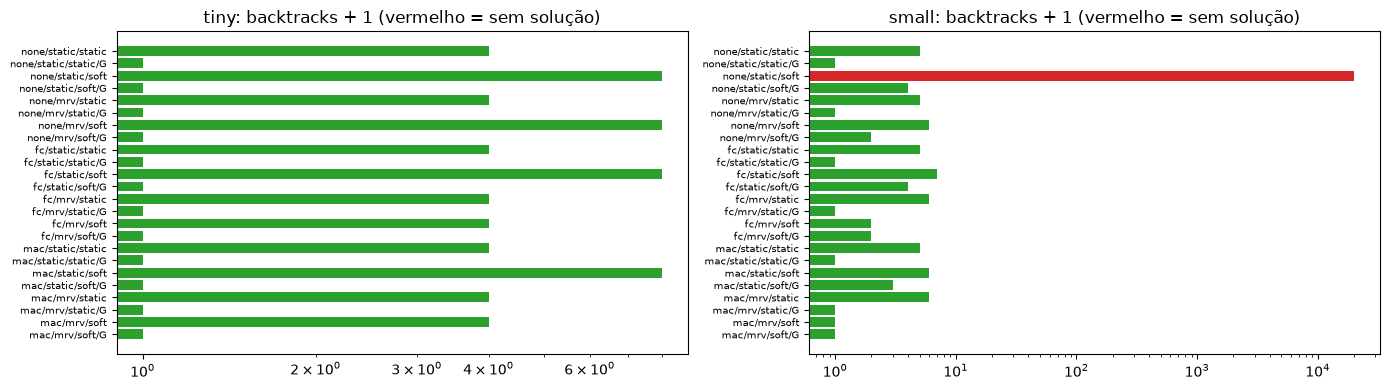

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ("tiny", "small")):
    runs = first_solutions[first_solutions.dataset == name].copy()
    runs["config"] = (runs.inference + "/" + runs.var_order + "/" + runs.value_order
                      + runs.global_fc.map({True: "/G", False: ""}))
    ax.barh(runs.config, runs.backtracks + 1, color=["tab:green" if pd.notna(km) else "tab:red" for km in runs.cost_km])
    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set_title(f"{name}: backtracks + 1 (vermelho = sem solução)")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()

## 5. A melhor configuração no small

{'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': False, 'status': 'viável', 'cost_km': 841.05, 'assignments': 37, 'backtracks': 0, 'checks': 5006, 'pruned': 135, 'solutions': 1, 'seconds': 0.37}
{'km': 841.05, 'feasible': True, 'trips': 8, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2508.4, 'route_min': 1555.8} | verificador: True


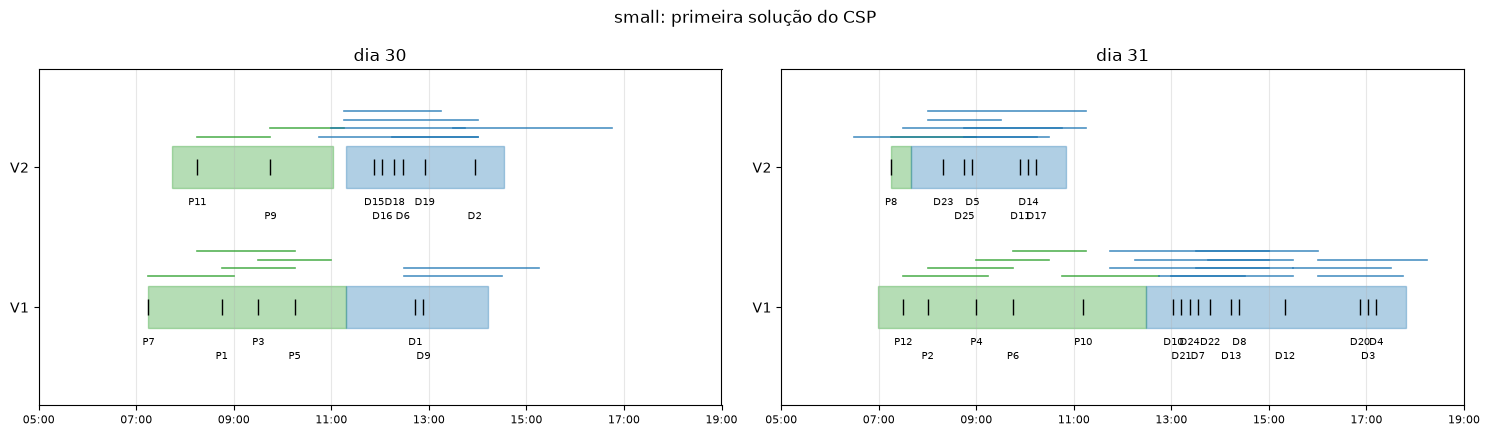

In [8]:
result = solve(small, inference="mac", var_order="mrv", value_order="soft", global_fc=True)
print(result.summary())
small_eval = evaluate(small, result.solution)
print(small_eval.summary(), "| verificador:", check_solution(small, small_eval).valid)
plot_gantt(small, small_eval, "small: primeira solução do CSP");

## 6. Sensibilidade ao modelo de posições

O modelo de posições fixa quantas viagens de cada tipo um veículo pode fazer por dia. Com poucas
posições, o problema pode ficar sem solução. Com muitas, o domínio cresce e aparecem simetrias, porque
uma posição vazia antes ou depois de outra dá a mesma solução. A tabela mostra o efeito, com FC global.

In [9]:
rows = []
for template in ("DPD", "DPDPD", "DPDDPDD", "DDPDDPDDD"):
    for name, problem in PROBLEMS.items():
        result = solve(problem, global_fc=True, template=tuple(template), max_assignments=5_000, time_limit=30)
        rows.append(dict(modelo=template, dataset=name, estado=result.status, km=result.cost,
                         atribuicoes=result.assignments, backtracks=result.backtracks,
                         segundos=round(result.seconds, 2)))
pd.DataFrame(rows).pivot(index="modelo", columns="dataset", values=["estado", "km", "backtracks"])

estado              km         backtracks     
dataset     small    tiny   small    tiny      small tiny
modelo                                                   
DDPDDPDDD  viável  viável  841.05  621.57          0    0
DPD        viável  viável  841.05  621.57          0    0
DPDDPDD    viável  viável  841.05  621.57          0    0
DPDPD      viável  viável  841.05  621.57          0    0

## 7. Restrição suave: branch & bound

Depois da primeira solução, a pesquisa continua com o limite km(parcial) < melhor km. O gráfico mostra
o melhor custo a descer à medida que as atribuições aumentam.

tiny {'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': True, 'status': 'melhor encontrada (limite)', 'cost_km': 621.57, 'assignments': 3000, 'backtracks': 2985, 'checks': 64638, 'pruned': 831, 'solutions': 1, 'seconds': 6.652}


small {'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': True, 'status': 'melhor encontrada (limite)', 'cost_km': 792.71, 'assignments': 3000, 'backtracks': 2973, 'checks': 62292, 'pruned': 1767, 'solutions': 4, 'seconds': 8.107}


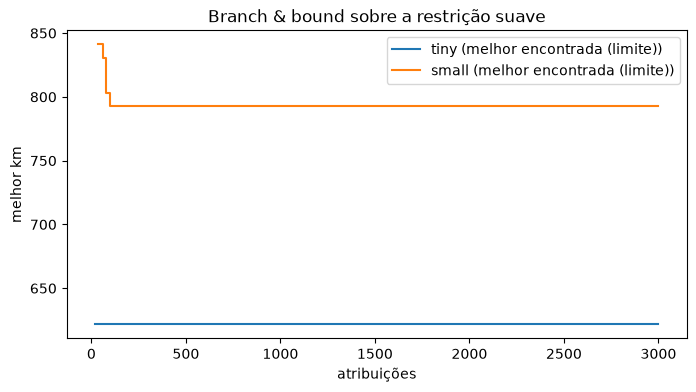

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, problem in PROBLEMS.items():
    result = solve(problem, global_fc=True, optimize=True, max_assignments=3_000, time_limit=60)
    assignments = [count for count, _, _ in result.improvements]
    best_km = [km for _, _, km in result.improvements]
    ax.step(assignments + [result.assignments], best_km + [best_km[-1]], where="post",
            label=f"{name} ({result.status})")
    print(name, result.summary())
ax.set_xlabel("atribuições")
ax.set_ylabel("melhor km")
ax.set_title("Branch & bound sobre a restrição suave")
ax.legend();

## 8. Conclusões

No tiny, o problema é pequeno e todas as configurações encontram solução com no máximo 7 backtracks.

No small vê-se para que serve a inferência. A restrição binária de sequência deixa o forward checking
retirar aos pedidos por atribuir as viagens que já não cabem no horário. Com a ordem *soft* e a ordem
estática das variáveis, o backtracking sem inferência entra em *thrashing* (sem solução após 20 000
atribuições), enquanto FC e MAC resolvem com 6 e 5 backtracks. Com MRV, sem inferência são precisos 5
backtracks, e FC e MAC descem para 1 e 0 (tabela da secção 4).

O AC-3 na raiz não remove nenhum valor, porque há sempre um valor de suporte noutro veículo ou noutra
viagem; ajuda durante a pesquisa, no MAC, quando os domínios já estão reduzidos. O FC global, que filtra
valores com o simulador, resolve o small quase sem backtracking em todas as configurações (no máximo
3). Cada nó fica mais caro e a árvore fica minúscula. O efeito nos km varia: com MAC, MRV e ordem *soft*,
a primeira solução melhora no tiny (621,57 contra 659,27 km) e piora no small (841,05 contra 806,18 km).

A ordenação *soft* dá primeiras soluções com menos km. No small, o branch & bound continua a melhorá-las
até o orçamento acabar (de 841,05 para 792,71 km), sem chegar a provar o ótimo. O modelo de posições é uma escolha de modelação: tem de
permitir viagens suficientes por dia, e posições a mais só aumentam o domínio e as simetrias.